In [1]:
import gymnasium as gym 
import numpy as np 
import random

In [2]:
gamma = 0.99
epsilon = 0.1
alpha = 0.5
episodes = 500

In [3]:
Q = np.zeros((48, 4))

In [4]:
# epsilon - policy

def epsilon_greedy(state):
    if random.random() < epsilon:
        return env.action_space.sample()   # Explore

    else:
        return np.argmax(Q[state])   # Expoit
        

In [5]:
# Q-learning

for episode in range(episodes):

    render = (episode % 50 == 0)

    if render:
        env = gym.make("CliffWalking-v1", render_mode="human")
    else:
        env = gym.make("CliffWalking-v1")

    done = False
    state, _ = env.reset()

    episode_len = 0
    tot_reward = 0

    while not done:
        action = epsilon_greedy(state)

        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Q-learning update
        Q[state, action] += alpha * (reward + gamma * np.max(Q[next_state]) - Q[state, action])

        state = next_state

        episode_len += 1
        tot_reward += reward

    print(f"episode={episode+1}/500 & total reward = {tot_reward} & episode len = {episode_len}")
    env.close()

episode=1/500 & total reward = -726 & episode len = 231
episode=2/500 & total reward = -955 & episode len = 361
episode=3/500 & total reward = -253 & episode len = 154
episode=4/500 & total reward = -85 & episode len = 85
episode=5/500 & total reward = -82 & episode len = 82
episode=6/500 & total reward = -35 & episode len = 35
episode=7/500 & total reward = -58 & episode len = 58
episode=8/500 & total reward = -319 & episode len = 121
episode=9/500 & total reward = -87 & episode len = 87
episode=10/500 & total reward = -145 & episode len = 46
episode=11/500 & total reward = -61 & episode len = 61
episode=12/500 & total reward = -47 & episode len = 47
episode=13/500 & total reward = -61 & episode len = 61
episode=14/500 & total reward = -22 & episode len = 22
episode=15/500 & total reward = -185 & episode len = 86
episode=16/500 & total reward = -44 & episode len = 44
episode=17/500 & total reward = -29 & episode len = 29
episode=18/500 & total reward = -39 & episode len = 39
episode=1

In [6]:
# what did our agent learn?

env = gym.make("CliffWalking-v1", render_mode="human")
state, _ = env.reset()
total_reward = 0
epsiode_len = 0
done = False

while not done:
    action = np.argmax(Q[state])
    state, reward, terminated, truncated, _ = env.step(action)
    done = terminated or truncated

    epsiode_len += 1
    total_reward += reward

print(f"total reward = {total_reward} & epsiode len = {epsiode_len}")
env.close()


total reward = -13 & epsiode len = 13


In [7]:
Q[36] # Q(s, a) state = 36

array([ -12.2478977 , -112.12535367,  -13.12541865,  -13.12540228])

In [8]:
Q[35] # Q(s, a) state = 35

array([-2.96958767, -1.98902834, -1.        , -2.94468649])

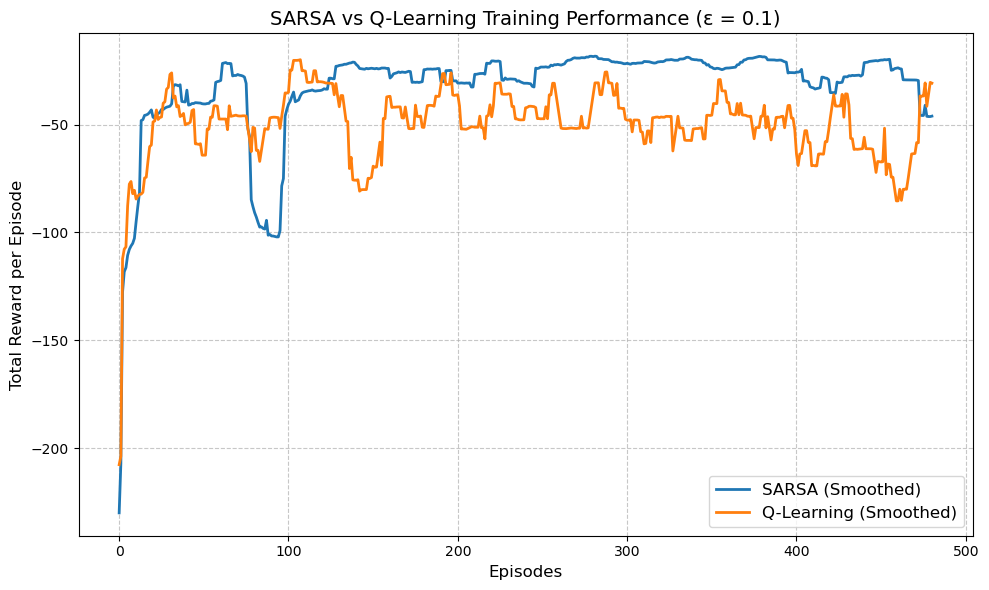

In [9]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

env = gym.make('CliffWalking-v1')
gamma, alpha, epsilon, episodes = 0.99, 0.5, 0.1, 500

# 1. Train SARSA
Q_sarsa = np.zeros((48, 4))
sarsa_rewards = []
for _ in range(episodes):
    state, _ = env.reset()
    action = env.action_space.sample() if random.random() < epsilon else np.argmax(Q_sarsa[state])
    tot_r, done = 0, False
    while not done:
        next_state, reward, term, trunc, _ = env.step(action)
        done = term or trunc
        next_action = env.action_space.sample() if random.random() < epsilon else np.argmax(Q_sarsa[next_state])
        Q_sarsa[state, action] += alpha * (reward + gamma * Q_sarsa[next_state, next_action] - Q_sarsa[state, action])
        state, action = next_state, next_action
        tot_r += reward
    sarsa_rewards.append(tot_r)

# 2. Train Q-Learning
Q_ql = np.zeros((48, 4))
ql_rewards = []
for _ in range(episodes):
    state, _ = env.reset()
    tot_r, done = 0, False
    while not done:
        action = env.action_space.sample() if random.random() < epsilon else np.argmax(Q_ql[state])
        next_state, reward, term, trunc, _ = env.step(action)
        done = term or trunc
        Q_ql[state, action] += alpha * (reward + gamma * np.max(Q_ql[next_state]) - Q_ql[state, action])
        state = next_state
        tot_r += reward
    ql_rewards.append(tot_r)

# 3. Plotting
plt.figure(figsize=(10, 6))
window = 20 # Smoothing window
sarsa_smoothed = np.convolve(sarsa_rewards, np.ones(window)/window, mode='valid')
ql_smoothed = np.convolve(ql_rewards, np.ones(window)/window, mode='valid')

plt.plot(sarsa_smoothed, label='SARSA (Smoothed)', color='#1f77b4', linewidth=2)
plt.plot(ql_smoothed, label='Q-Learning (Smoothed)', color='#ff7f0e', linewidth=2)

plt.xlabel('Episodes', fontsize=12)
plt.ylabel('Total Reward per Episode', fontsize=12)
plt.title('SARSA vs Q-Learning Training Performance (ε = 0.1)', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('reward_plot.png', dpi=300)
plt.show()
